In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from outliers import smirnov_grubbs as grubbs
from pyampute.exploration.mcar_statistical_tests import MCARTest

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
RAW_PATH = "budget_nfhs_combined.csv"
df_raw = pd.read_csv(RAW_PATH)

# A few source headers carry a stray leading space (for example " Households using iodized
# salt (%)"), which silently breaks later column lookups by exact name, so strip immediately.
df_raw.columns = [c.strip() for c in df_raw.columns]

print("Shape:", df_raw.shape)
df_raw.head()


Shape: (29, 50)


,State,Population (Total),Accounts,Budget Estimates,Revised Estimates,Population below age 15 years (%),"Sex ratio of the total population (females per 1,000 males)","Sex ratio at birth for children born in the last five years (females per 1,000 males)",Children under age 5 years whose birth was registered with the civil authority (%),Population living in households with an improved drinking-water source1 (%),Population living in households that use an improved sanitation facility2 (%),Households using iodized salt (%),Children age 5 years who attended pre-primary school during the school year 2019-20 (%),Women age 15-19 years who were already mothers or pregnant at the time of the survey (%),Adolescent fertility rate for women age 15-19 years,Neonatal mortality rate (NNMR),Infant mortality rate (IMR),Under-five mortality rate (U5MR),Mothers who had an antenatal check-up in the first trimester (%),Mothers who had at least 4 antenatal care visits (%),Mothers whose last birth was protected against neonatal tetanus9 (%),Mothers who consumed iron folic acid for 180 days or more when they were pregnant (%),Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%),Children who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),Institutional births (%),Home births that were conducted by skilled health personnel10 (%),Children age 12-23 months fully vaccinated based on information from either vaccination card or mother's recall11 (%),Children age 12-23 months fully vaccinated based on information from vaccination card only12 (%),Children age 12-23 months who have received BCG (%),Children age 12-23 months who have received 3 doses of polio vaccine13 (%),Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%),Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%),Children age 24-35 months who have received a second dose of measles-containing vaccine (MCV) (%),Children age 12-23 months who have received 3 doses of rotavirus vaccine14 (%),Children age 12-23 months who have received 3 doses of penta or hepatitis B vaccine (%),Children age 9-59 months who received a vitamin A dose in the last 6 months (%),Children age 12-23 months who received most of their vaccinations in a public health facility (%),Children age 12-23 months who received most of their vaccinations in a private health facility (%),Prevalence of diarrhoea in the 2 weeks preceding the survey (%),Children under age 3 years breastfed within one hour of birth15 (%),Children under age 6 months exclusively breastfed16 (%),Children age 6-8 months receiving solid or semi-solid food and breastmilk16 (%),"Breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)","Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)","Total children age 6-23 months receiving an adequate diet16, 17 (%)",Children under 5 years who are stunted (height-for-age)18 (%),Children under 5 years who are wasted (weight-for-height)18 (%),Children under 5 years who are severely wasted (weight-for-height)19 (%),Children under 5 years who are underweight (weight-for-age)18 (%),Children under 5 years who are overweight (weight-for-height)20 (%)
0,Andhra Pradesh,"5,25,04,000","5,25,929.60",605549.45,526323.02,21.3,1024,877,93.8,99.4,89.1,89.3,10.2,9.3,40,14.4,29.8,33.7,82.7,67.2,92.5,45.6,NaN,92.9,98.6,1.0,69.3,89.1,92.4,70.6,84.8,83.7,27.1,72.0,83.0,81.7,86.4,11.5,6.2,51.6,61.4,67.3,15.2,19.5,16.7,23.1,17.6,6.4,25.1,3.0
1,Arunachal Pradesh,"15,19,000",92615,131266.59,91612.2,26.2,989,912,89.7,98.1,79.9,99.4,8.0,3.2,27,12.5,16.7,22.2,57.2,47.8,82.1,13.0,7.8,66.6,90.6,3.2,66.8,73.4,93.4,70.5,83.2,85.1,29.6,28.8,80.9,75.7,99.3,0.7,4.3,54.0,66.2,42.3,26.5,16.8,25.7,28.4,10.1,4.7,13.1,9.6
2,Assam,"3,46,68,000",451977.3,591193.62,633180.84,21.3,982,916,97.0,92.3,69.7,99.6,4.1,5.8,41,15.2,22.7,33.0,72.7,62.

## Data Inspection

In [ ]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 50 columns):
 #   Column                                                                                                                         Non-Null Count  Dtype  
---  ------                                                                                                                         --------------  -----  
 0   State                                                                                                                          29 non-null     str    
 1   Population (Total)                                                                                                             29 non-null     str    
 2   Accounts                                                                                                                       29 non-null     str    
 3   Budget Estimates                                                                                                           

In [71]:
df_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State,29,29,Andhra Pradesh,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Population (Total),29,29,"5,25,04,000",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Accounts,29,29,"5,25,929.60",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Budget Estimates,29,29,605549.45,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revised Estimates,29,29,526323.02,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Population below age 15 years (%),29.0,NaN,NaN,NaN,23.048276,2.959925,19.2,21.0,22.2,24.7,31.6
"Sex ratio of the total population (females per 1,000 males)",29.0,NaN,NaN,NaN,995.965517,55.629182,911.0,956.0,985.0,1024.0,1138.0
"Sex ratio at birth for children born in the last five years (females per 1,000 males)",29.0,NaN,NaN,NaN,949.482759,128.397157,781.0,893.0,933.0,950.0,1520.0
Children under age 5 years whose birth was registered with the civil authority (%),29.0,NaN,NaN,NaN,93.686207,6.242179,75.4,92.2,95.6,97.9,100.0
Population living in households with an improved drinking-water source1 (%),29.0,NaN,NaN,NaN,97.634483,2.419013,90.4,97.3,98.4,99.3,99.6


Population (Total), Accounts, Budget Estimates and Revised
Estimates show up as object rather than numeric. Reason is because the source uses the Indian numbering system with commas, which pandas cannot parse automatically.

In [5]:
df_raw[["State", "Population (Total)", "Accounts", "Budget Estimates", "Revised Estimates"]].head()


,State,Population (Total),Accounts,Budget Estimates,Revised Estimates
0,Andhra Pradesh,"5,25,04,000","5,25,929.60",605549.45,526323.02
1,Arunachal Pradesh,"15,19,000",92615,131266.59,91612.2
2,Assam,"3,46,68,000",451977.3,591193.62,633180.84
3,Bihar,"12,13,02,000",611797.7,"6,38,425.20","7,24,500.80"
4,Chattisgarh,"2,91,09,000",404904.7,"4,03,411.10","4,42,702.30"


## Fixing data types

In [6]:
df = df_raw.copy()

money_cols = ["Population (Total)", "Accounts", "Budget Estimates", "Revised Estimates"]

for c in money_cols:
    df[c] = (
        df[c]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip()
        .astype(float)
    )

df["State"] = df["State"].str.strip()

df[money_cols].describe()


,Population (Total),Accounts,Budget Estimates,Revised Estimates
count,2.900000e+01,2.900000e+01,2.900000e+01,2.900000e+01
mean,4.560066e+07,4.506780e+05,4.805445e+05,4.812330e+05
std,5.072978e+07,3.472663e+05,3.685084e+05,3.691624e+05
min,6.700000e+05,3.604670e+04,3.587860e+04,3.949860e+04
25%,4.032000e+06,9.298630e+04,1.312666e+05,1.060341e+05
50%,3.466800e+07,4.049047e+05,4.034111e+05,4.427023e+05
75%,6.886200e+07,6.742422e+05,6.912670e+05,7.245008e+05
max,2.279430e+08,1.245497e+06,1.363618e+06,1.370988e+06


## Feature engineering: per-capita health expenditure

Accounts (actual or audited spend), Budget Estimates and Revised Estimates are absolute
figures in Rs. lakh, so they are not directly comparable across states of very different
population size. A large state will always out-spend a small one in absolute terms even if it
spends less per person. So we create a normalized feature of spending per person

In [7]:
df["Per_Capita_Health_Exp_Accounts"] = df["Accounts"]          * 1e5 / df["Population (Total)"]
df["Per_Capita_Health_Exp_BE"]       = df["Budget Estimates"]  * 1e5 / df["Population (Total)"]
df["Per_Capita_Health_Exp_RE"]       = df["Revised Estimates"] * 1e5 / df["Population (Total)"]

exp_cols = ["Per_Capita_Health_Exp_Accounts", "Per_Capita_Health_Exp_BE", "Per_Capita_Health_Exp_RE"]
df[["State"] + exp_cols].sort_values("Per_Capita_Health_Exp_Accounts", ascending=False)


,State,Per_Capita_Health_Exp_Accounts,Per_Capita_Health_Exp_BE,Per_Capita_Health_Exp_RE
1,Arunachal Pradesh,6097.103357,8641.645161,6031.086241
5,Goa,6002.989025,6853.783086,6845.326017
22,Sikkim,5380.104478,5355.014925,5895.313433
17,Mizoram,4220.332226,4286.951827,4812.732558
18,Nagaland,2875.697835,3176.144634,3177.535698
9,Jammu and Kashmir,2646.332206,2712.886885,3112.501315
16,Meghalaya,2321.738329,3068.931204,3068.931204
8,Himachal Pradesh,2261.528515,2668.029128,2656.041922
15,Manipur,1915.603063,2227.054882,2294.262923
12,Kerala,1909.655876,1808.166086,1838.365480


## Visual data inspection

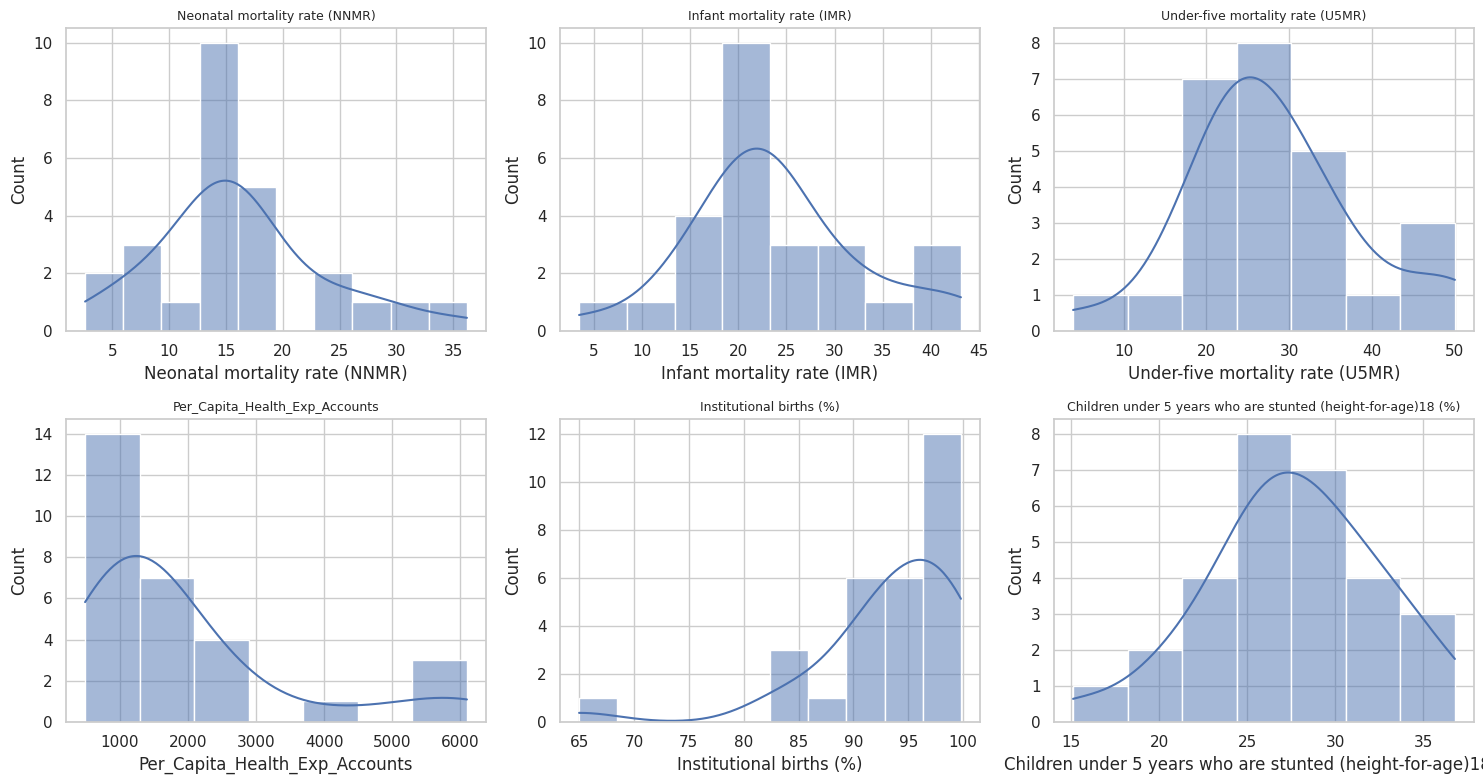

In [8]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

key_vars = [
    "Neonatal mortality rate (NNMR)",
    "Infant mortality rate (IMR)",
    "Under-five mortality rate (U5MR)",
    "Per_Capita_Health_Exp_Accounts",
    "Institutional births (%)",
    "Children under 5 years who are stunted (height-for-age)18 (%)",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, key_vars):
    sns.histplot(df[col].dropna(), kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()


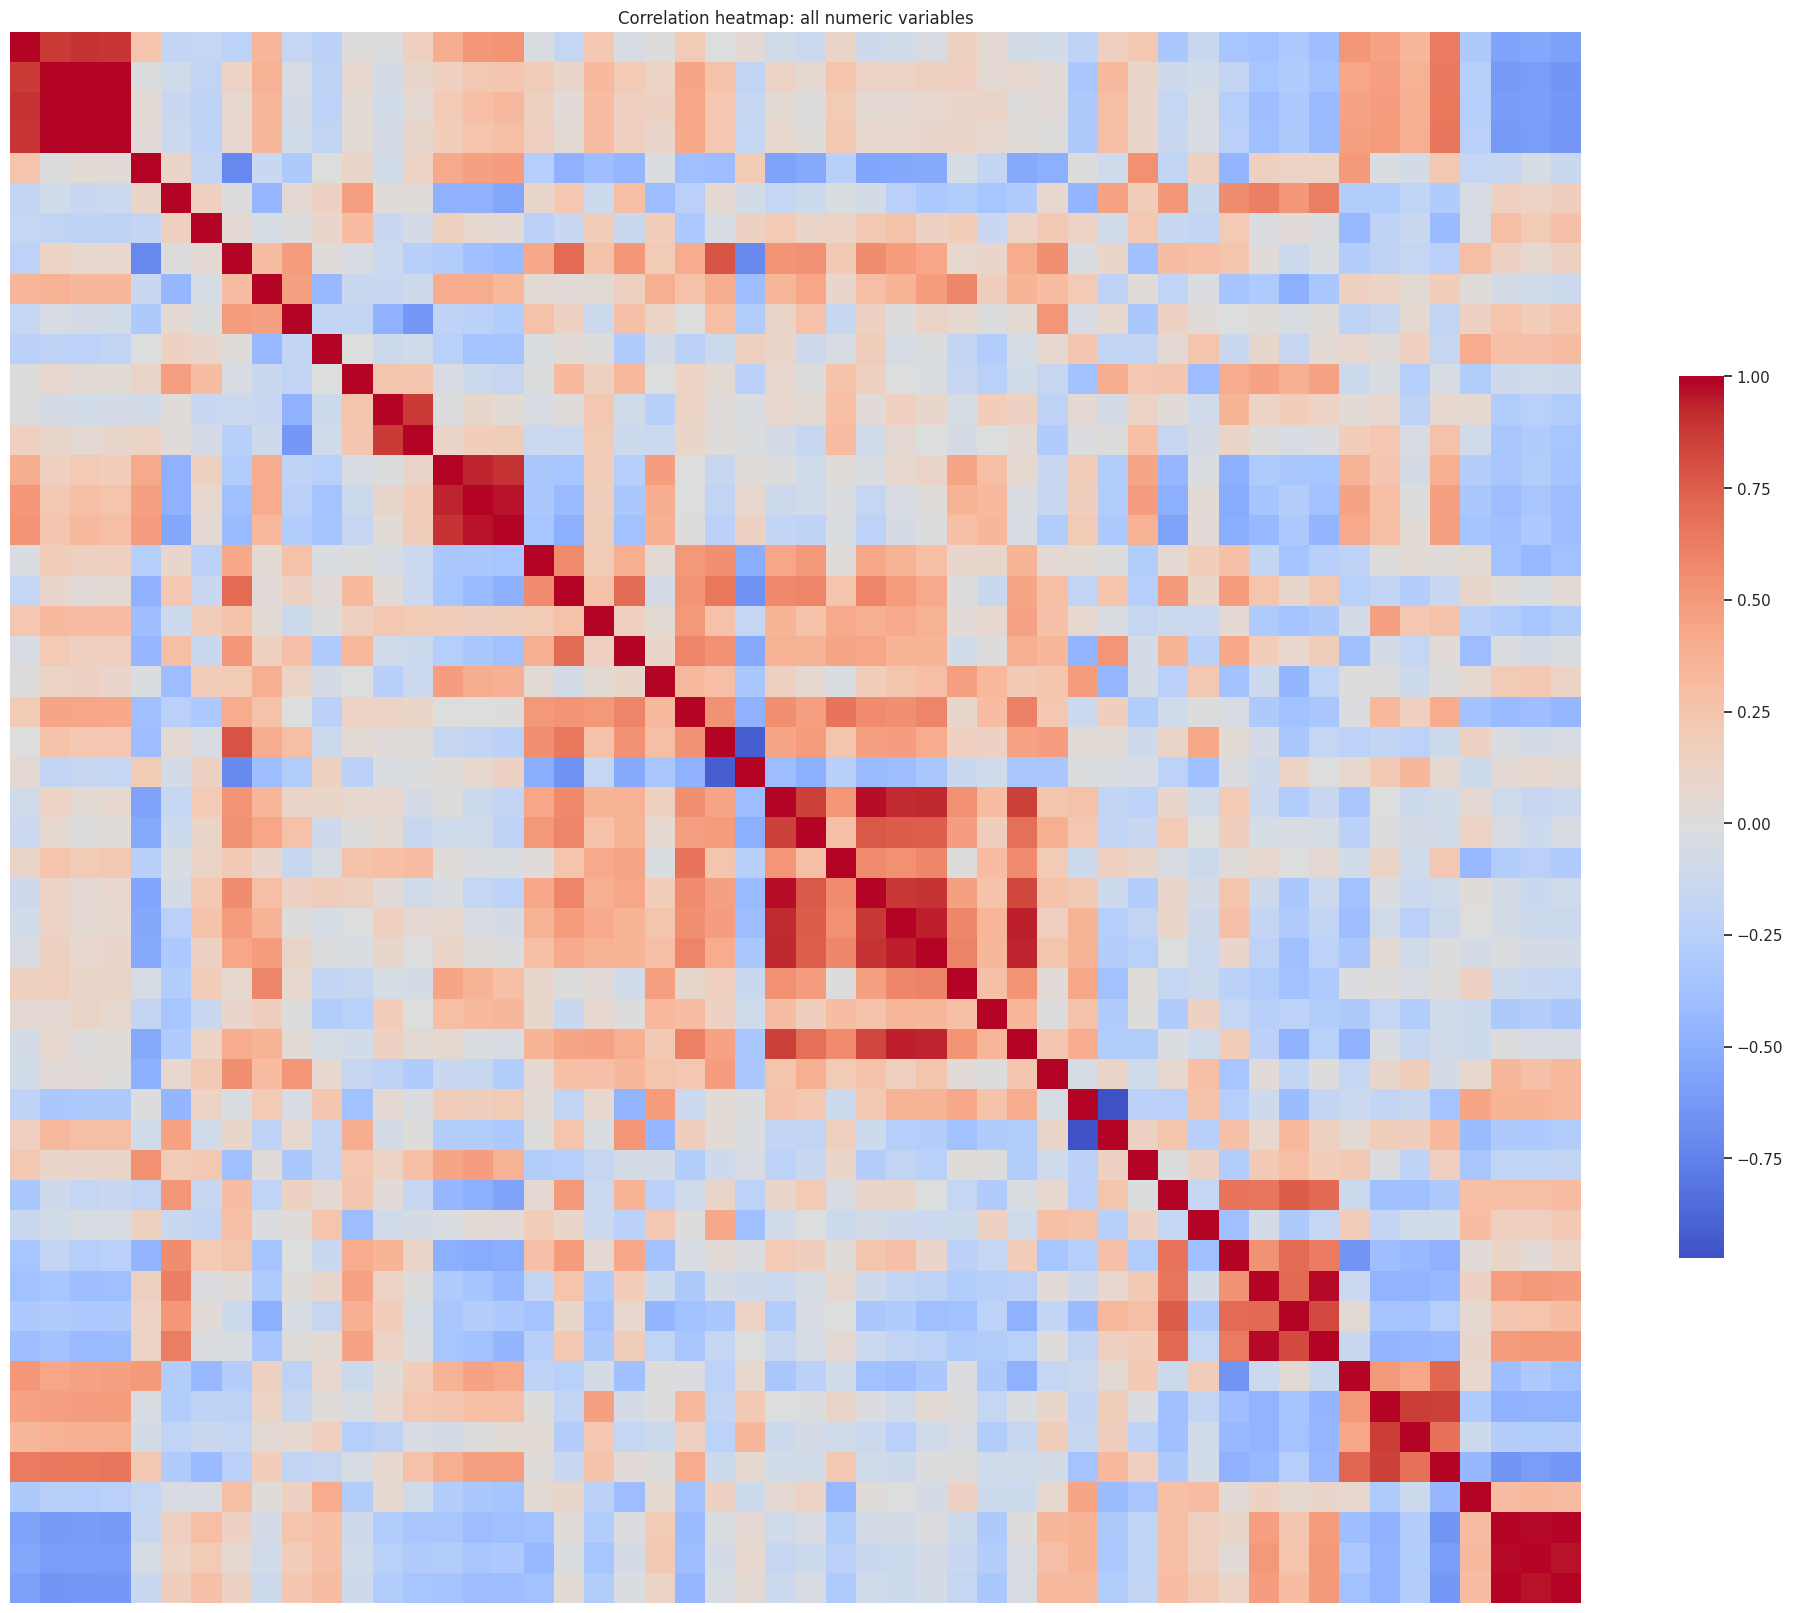

In [9]:
fig, ax = plt.subplots(figsize=(20, 18))
corr = df[numeric_cols].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, ax=ax,
            cbar_kws={"shrink": 0.5}, xticklabels=False, yticklabels=False)
ax.set_title("Correlation heatmap: all numeric variables")
plt.tight_layout()
plt.show()


Large solid blocks of dark red indicate clusters of
near-duplicate indicators. For example, the vaccination-coverage variables are all tightly correlated with each other, which makes sense since they are collected in the same survey module and states that vaccinate well tend
to do so across the board. This correlation structure is exactly what we lean on later when
choosing which features to impute a missing value from.

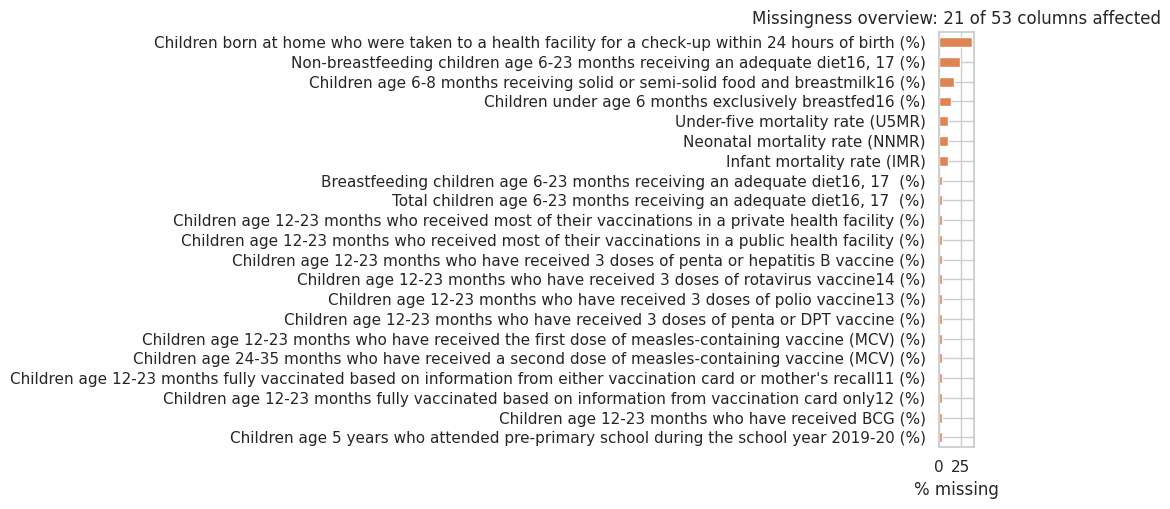

In [10]:
na_counts_preview = df.isna().sum()
na_pct_preview = (na_counts_preview / len(df) * 100).round(1)
preview = pd.DataFrame({"n_missing": na_counts_preview, "pct_missing": na_pct_preview}).query("n_missing > 0")

fig, ax = plt.subplots(figsize=(10, max(4, 0.25 * len(preview))))
preview["pct_missing"].sort_values().plot.barh(ax=ax, color="#DD8452")
ax.set_xlabel("% missing")
ax.set_title(f"Missingness overview: {len(preview)} of {df.shape[1]} columns affected")
plt.tight_layout()
plt.show()


## Duplicate check

In [11]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate state names:", df['State'].duplicated().sum())
print("Row count vs expected state count:", len(df), "rows for", df['State'].nunique(), "unique states")


Fully duplicated rows: 0
Duplicate state names: 0
Row count vs expected state count: 29 rows for 29 unique states


**Result.** No duplicate rows and no duplicate state names: 29 rows for 29 unique
states

## Outlier detection

We tested on different type of methods such as Univariate tests : IQR method, Z-score, Grubs and Multivariate tests : LOF, DBSCAN to produce a more confident and robust result. 

### IQR method

In [12]:
def iqr_outlier_report(data, cols):
    rows = []
    for c in cols:
        s = data[c].dropna()
        if s.empty:
            continue
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (s < lo) | (s > hi)
        if mask.sum() > 0:
            rows.append({
                "column": c,
                "n_outliers": int(mask.sum()),
                "lower_bound": round(lo, 2),
                "upper_bound": round(hi, 2),
                "outlier_states": data.loc[s[mask].index, "State"].tolist(),
            })
    return pd.DataFrame(rows).sort_values("n_outliers", ascending=False)

iqr_report = iqr_outlier_report(df, numeric_cols)
iqr_report


,column,n_outliers,lower_bound,upper_bound,outlier_states
3,Sex ratio at birth for children born in the la...,4,807.50,1.035500e+03,"[Jharkhand, Karnataka, Sikkim, Uttarkhand]"
5,Population living in households with an improv...,4,94.30,1.023000e+02,"[Assam, Manipur, Meghalaya, Nagaland]"
10,Neonatal mortality rate (NNMR),4,5.55,2.655000e+01,"[Bihar, Kerala, Uttarkhand, Uttar Pradesh]"
28,Per_Capita_Health_Exp_Accounts,4,-866.85,4.138560e+03,"[Arunachal Pradesh, Goa, Mizoram, Sikkim]"
27,Children under 5 years who are overweight (wei...,4,0.50,8.500000e+00,"[Arunachal Pradesh, Jammu and Kashmir, Mizoram..."
15,Children who received postnatal care from a do...,4,60.95,1.093500e+02,"[Meghalaya, Mizoram, Nagaland, Sikkim]"
11,Infant mortality rate (IMR),3,8.56,3.966000e+01,"[Bihar, Kerala, Uttar Pradesh]"
22,Prevalence of diarrhoea in the 2 weeks precedi...,3,0.45,9.650000e+00,"[Bihar, Meghalaya, Odisha]"
30,Per_Capita_Health_Exp_RE,3,-1430.71,5.108100e+03,"[Arunachal Pradesh, Goa, Sikkim]"
23,Breastfeeding children age 6-23 months receivi...,3,-0.67,2.512000e+01,"[Arunachal Pradesh, Meghalaya, West Bengal]"


### Modified Z-score (MAD-based)

In [13]:
def modified_zscore_outlier_report(data, cols, threshold=3.5):
    rows = []
    for c in cols:
        s = data[c].dropna()
        if s.empty:
            continue
        median = s.median()
        mad = (s - median).abs().median()
        if mad == 0:
            continue  # modified z-score undefined when MAD is 0 (e.g. near-constant column)
        mod_z = 0.6745 * (s - median) / mad
        mask = mod_z.abs() > threshold
        if mask.sum() > 0:
            rows.append({
                "column": c,
                "n_outliers": int(mask.sum()),
                "outlier_states": data.loc[s[mask].index, "State"].tolist(),
            })
    return pd.DataFrame(rows).sort_values("n_outliers", ascending=False)

modz_report = modified_zscore_outlier_report(df, numeric_cols)
modz_report


,column,n_outliers,outlier_states
19,Per_Capita_Health_Exp_Accounts,4,"[Arunachal Pradesh, Goa, Mizoram, Sikkim]"
21,Per_Capita_Health_Exp_RE,4,"[Arunachal Pradesh, Goa, Mizoram, Sikkim]"
20,Per_Capita_Health_Exp_BE,4,"[Arunachal Pradesh, Goa, Mizoram, Sikkim]"
7,Adolescent fertility rate for women age 15-19 ...,2,"[Bihar, Tripura]"
4,Population living in households with an improv...,2,"[Assam, Manipur]"
3,Children under age 5 years whose birth was reg...,2,"[Bihar, Nagaland]"
18,Children under 5 years who are overweight (wei...,2,"[Jammu and Kashmir, Mizoram]"
8,Neonatal mortality rate (NNMR),2,"[Bihar, Uttarkhand]"
0,Population (Total),1,[Uttar Pradesh]
1,Population below age 15 years (%),1,[Bihar]


### Grubbs' test

In [14]:
def grubbs_outlier_report(data, cols, alpha=0.05):
    rows = []
    for c in cols:
        s = data[c].dropna()
        if len(s) < 7:  # Grubbs' test is unreliable / undefined for very small samples
            continue
        try:
            outlier_idx = grubbs.two_sided_test_indices(s.values, alpha=alpha)
        except Exception:
            continue
        if len(outlier_idx) > 0:
            flagged_index = s.index[outlier_idx]
            rows.append({
                "column": c,
                "n_outliers": len(outlier_idx),
                "outlier_states": data.loc[flagged_index, "State"].tolist(),
                "outlier_values": s.iloc[outlier_idx].round(2).tolist(),
            })
    return pd.DataFrame(rows).sort_values("n_outliers", ascending=False)

grubbs_report = grubbs_outlier_report(df, numeric_cols)
grubbs_report


,column,n_outliers,outlier_states,outlier_values
15,Per_Capita_Health_Exp_BE,4,"[Arunachal Pradesh, Goa, Sikkim, Mizoram]","[8641.65, 6853.78, 5355.01, 4286.95]"
0,Population (Total),1,[Uttar Pradesh],[227943000.0]
2,Sex ratio at birth for children born in the la...,1,[Sikkim],[1520]
1,Population below age 15 years (%),1,[Bihar],[31.6]
4,Population living in households with an improv...,1,[Manipur],[90.4]
5,Households using iodized salt (%),1,[Andhra Pradesh],[89.3]
6,Women age 15-19 years who were already mothers...,1,[Tripura],[14.4]
3,Children under age 5 years whose birth was reg...,1,[Bihar],[75.4]
7,Children who received postnatal care from a do...,1,[Mizoram],[39.7]
8,Institutional births (%),1,[Nagaland],[65.0]


### DBSCAN (multivariate, density based)

Before DBSCAN, we do PCA to avoid curse of dimensionality

Reduced 52 standardized columns to 13 principal components (90% variance retained) for distance-based outlier detection.


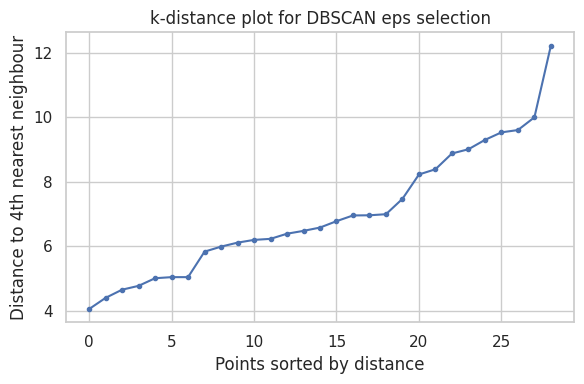

In [15]:
X_for_outliers = pd.DataFrame(
    SimpleImputer(strategy="mean").fit_transform(df[numeric_cols]),
    columns=numeric_cols, index=df.index,
)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_for_outliers)

pca_outliers = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_pca = pca_outliers.fit_transform(X_scaled)
print(f"Reduced {X_scaled.shape[1]} standardized columns to {X_pca.shape[1]} "
      f"principal components (90% variance retained) for distance-based outlier detection.")

# eps chosen from the k-distance elbow plot for the 4th-nearest neighbour in PCA space, a
# standard, data-driven way to set DBSCAN's eps rather than guessing a number.
k_dist = np.sort(NearestNeighbors(n_neighbors=4).fit(X_pca).kneighbors(X_pca)[0][:, -1])
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(k_dist, marker="o", markersize=3)
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel("Distance to 4th nearest neighbour")
ax.set_title("k-distance plot for DBSCAN eps selection")
plt.tight_layout()
plt.show()


In [16]:
dbscan = DBSCAN(eps=7.5, min_samples=3)
db_labels = dbscan.fit_predict(X_pca)

dbscan_flagged = df.loc[db_labels == -1, ["State"]].copy()
dbscan_flagged["dbscan_label"] = "noise / outlier"
print(f"DBSCAN flagged {len(dbscan_flagged)} of {len(df)} states as noise "
      f"(eps=7.5 from the elbow above, min_samples=3, on PCA-reduced space).")
dbscan_flagged


DBSCAN flagged 6 of 29 states as noise (eps=7.5 from the elbow above, min_samples=3, on PCA-reduced space).


,State,dbscan_label
1,Arunachal Pradesh,noise / outlier
15,Manipur,noise / outlier
16,Meghalaya,noise / outlier
17,Mizoram,noise / outlier
18,Nagaland,noise / outlier
22,Sikkim,noise / outlier


### Local Outlier Factor (LOF)

In [17]:
lof = LocalOutlierFactor(n_neighbors=5)
lof_labels = lof.fit_predict(X_pca)  # -1 = outlier, 1 = inlier
lof_scores = -lof.negative_outlier_factor_  # higher = more outlier-like

lof_flagged = df.loc[lof_labels == -1, ["State"]].copy()
lof_flagged["lof_score"] = lof_scores[lof_labels == -1].round(2)
print(f"LOF flagged {len(lof_flagged)} of {len(df)} states (n_neighbors=5, PCA-reduced space).")
lof_flagged.sort_values("lof_score", ascending=False)


LOF flagged 2 of 29 states (n_neighbors=5, PCA-reduced space).


,State,lof_score
18,Nagaland,1.60
16,Meghalaya,1.51


### Cross-method agreement

A state or column combination flagged by only one method out of five, at n = 29, is weak
evidence. We only treat a finding as a genuine candidate for action if it shows up under at
least two independent methods, either one univariate and one multivariate method, or two
univariate methods that use different assumptions.

In [18]:
multivariate_flags = set(dbscan_flagged["State"]) | set(lof_flagged["State"])
both_multivariate = set(dbscan_flagged["State"]) & set(lof_flagged["State"])

print("States flagged by DBSCAN:", sorted(dbscan_flagged["State"]))
print("States flagged by LOF:   ", sorted(lof_flagged["State"]))
print("States flagged by BOTH multivariate methods:", sorted(both_multivariate))

univariate_states = set()
for rep in [iqr_report, modz_report, grubbs_report]:
    for lst in rep.get("outlier_states", []):
        univariate_states.update(lst)

corroborated = multivariate_flags & univariate_states
print("\nMultivariate-flagged states that ALSO show up in at least one univariate flag:", sorted(corroborated))


States flagged by DBSCAN: ['Arunachal Pradesh', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Sikkim']
States flagged by LOF:    ['Meghalaya', 'Nagaland']
States flagged by BOTH multivariate methods: ['Meghalaya', 'Nagaland']

Multivariate-flagged states that ALSO show up in at least one univariate flag: ['Arunachal Pradesh', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Sikkim']


### Decision

Across all five methods, the flagged points are a small number of states that are genuinely
structurally different, for example small hill or north-eastern states with very different
population scale, spending levels and survey logistics from the large plains states, not
data-entry errors. Every flagged value is a plausible, in-range figure for that state, and no
method flags an impossible value such as a percentage outside 0 to 100 or negative expenditure.
Given the small sample size and that cross-state variation is exactly the signal this project is
trying to explain, not noise to be cleaned away, we do not remove, cap or winsorize any
outliers. They are retained and carried forward as a note of caution for the correlation or
regression analysis in the next stage of the project, for example by considering a robust or
rank-based correlation, or a sensitivity check with and without the flagged states.

## Missing value analysis

### Counts and percentages

In [19]:
na_counts = df.isna().sum()
na_pct = (na_counts / len(df) * 100).round(1)

missing_summary = (
    pd.DataFrame({"n_missing": na_counts, "pct_missing": na_pct})
    .query("n_missing > 0")
    .sort_values("n_missing", ascending=False)
)
missing_cols = missing_summary.index.tolist()
print(f"{len(missing_cols)} of {df.shape[1]} columns have at least one missing value "
      f"(out of {len(df)} rows).")
missing_summary


21 of 53 columns have at least one missing value (out of 29 rows).


,n_missing,pct_missing
Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%),11,37.9
"Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)",7,24.1
Children age 6-8 months receiving solid or semi-solid food and breastmilk16 (%),5,17.2
Children under age 6 months exclusively breastfed16 (%),4,13.8
Infant mortality rate (IMR),3,10.3
Neonatal mortality rate (NNMR),3,10.3
Under-five mortality rate (U5MR),3,10.3
Children age 5 years who attended pre-primary school during the school year 2019-20 (%),1,3.4
Children age 12-23 months fully vaccinated based on information from either vaccination card or mother's recall11 (%),1,3.4
Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%),1,3.4


### Missingness pattern across states

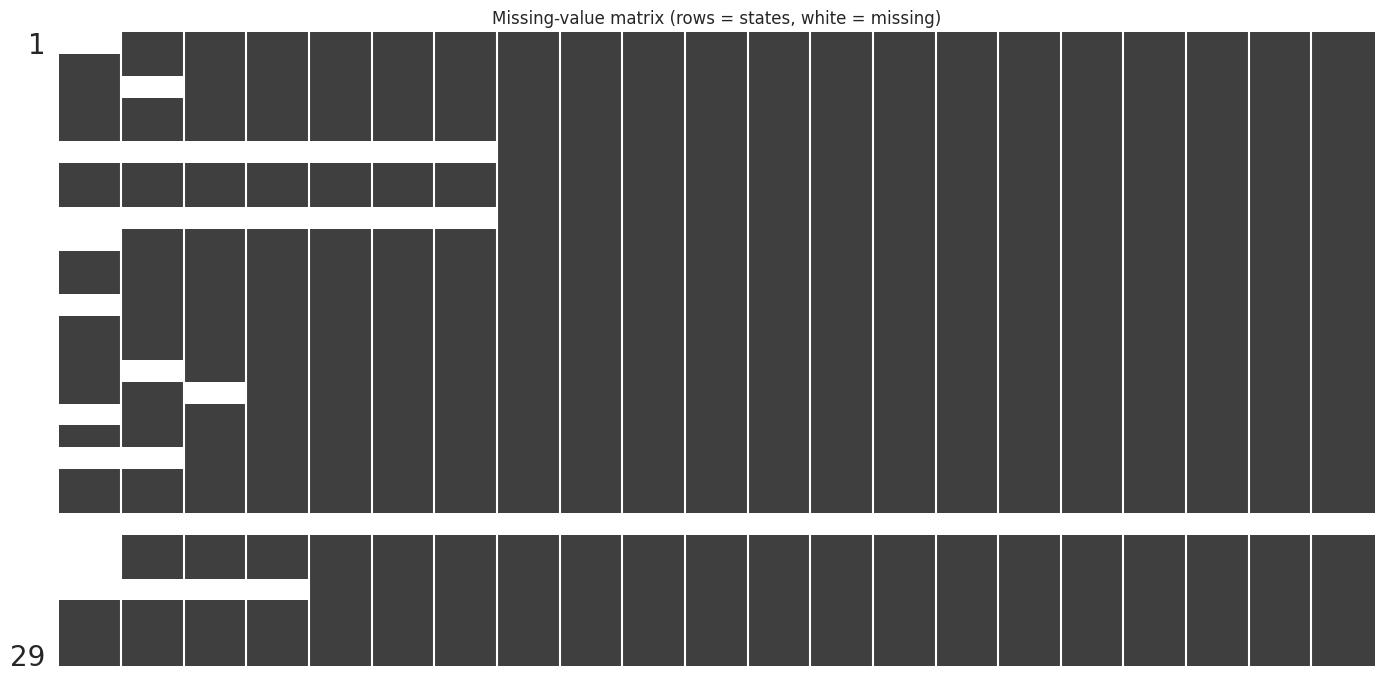

In [20]:
fig, ax = plt.subplots(figsize=(14, 7))
msno.matrix(df[missing_cols], ax=ax, sparkline=False, labels=False)
ax.set_title("Missing-value matrix (rows = states, white = missing)")
plt.tight_layout()
plt.show()


In [21]:
df.loc[df[missing_cols].isna().any(axis=1), ["State"] + missing_cols].style.highlight_null(color="salmon")


,State,Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%),"Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)",Children age 6-8 months receiving solid or semi-solid food and breastmilk16 (%),Children under age 6 months exclusively breastfed16 (%),Infant mortality rate (IMR),Neonatal mortality rate (NNMR),Under-five mortality rate (U5MR),Children age 5 years who attended pre-primary school during the school year 2019-20 (%),Children age 12-23 months fully vaccinated based on information from either vaccination card or mother's recall11 (%),Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%),Children age 12-23 months fully vaccinated based on information from vaccination card only12 (%),Children age 12-23 months who have received BCG (%),Children age 12-23 months who have received 3 doses of polio vaccine13 (%),Children age 12-23 months who have received 3 doses of rotavirus vaccine14 (%),Children age 24-35 months who have received a second dose of measles-containing vaccine (MCV) (%),Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%),Children age 12-23 months who have received 3 doses of penta or hepatitis B vaccine (%),Children age 12-23 months who received most of their vaccinations in a private health facility (%),Children age 12-23 months who received most of their vaccinations in a public health facility (%),"Breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)","Total children age 6-23 months receiving an adequate diet16, 17 (%)"
0,Andhra Pradesh,nan,19.500000,67.300000,61.400000,29.800000,14.400000,33.700000,10.200000,69.300000,84.800000,89.100000,92.400000,70.600000,72.000000,27.100000,83.700000,83.000000,11.500000,86.400000,15.200000,16.700000
2,Assam,2.800000,nan,57.600000,67.300000,22.700000,15.200000,33.000000,4.100000,63.200000,79.700000,70.600000,92.600000,69.300000,44.800000,12.500000,77.300000,72.700000,9.200000,88.400000,8.300000,7.900000
5,Goa,nan,nan,nan,nan,nan,nan,nan,19.500000,77.900000,89.300000,87.700000,96.500000,83.800000,2.300000,23.200000,92.900000,95.200000,9.200000,90.800000,18.900000,21.100000
8,Himachal Pradesh,nan,nan,nan,nan,nan,nan,nan,12.300000,94.100000,94.100000,100.000000,97.700000,95.400000,73.400000,30.600000,96.400000,94.100000,5.100000,93.600000,15.100000,14.400000
9,Jammu and Kashmir,nan,15.000000,44.300000,68.100000,14.700000,7.500000,15.700000,4.000000,83.000000,90.000000,99.800000,91.000000,83.000000,4.000000,36.500000,88.700000,88.000000,1.200000,98.800000,11.900000,12.300000
12,Kerala,nan,14.300000,73.100000,50.300000,3.500000,2.600000,3.900000,33.100000,77.600000,86.100000,83.300000,98.200000,85.800000,10.000000,16.900000,86.400000,85.300000,16.100000,83.900000,22.200000,21.500000
15,Manipur,0.000000,nan,83.500000,65.700000,12.200000,5.700000,17.100000,31.300000,75.100000,87.800000,79.600000,95.200000,80.700000,9.600000,18.100000,83.700000,87.500000,11.400000,88.600000,19.600000,20.000000
16,Meghalaya,0.000000,43.700000,nan,64.500000,23.400000,14.200000,23.400000,36.300000,58.300000,69.600000,76.000000,93.100000,63.500000,5.500000,12.200000,70.400000,56.000000,17.000000,78.300000,37.500000,39.500000
17,Mizoram,nan,13.900000,63.600000,74.300000,20.600000,14.400000,21.800000,6.900000,69.600000,81.600000,82.200000,81.500000,73.900000,14.400000,35.000000,79.900000,74.600000,5.200000,94.800000,16.200000,15.900000
19,Odisha,nan,nan,51.100000,68.300000,31.200000,24.600000,32.000000,8.500000,92.000000,98.400000,93.400000,98.200000,92.600000,90.600000,39.200000,97.700000,98.400000,6.800000,91.800000,14.000000,14.700000


### Co-missingness structure

If several columns go missing together for the same rows, that is a clue the missingness has a
shared cause, such as a whole survey module being skipped for one state, rather than each
column failing independently.

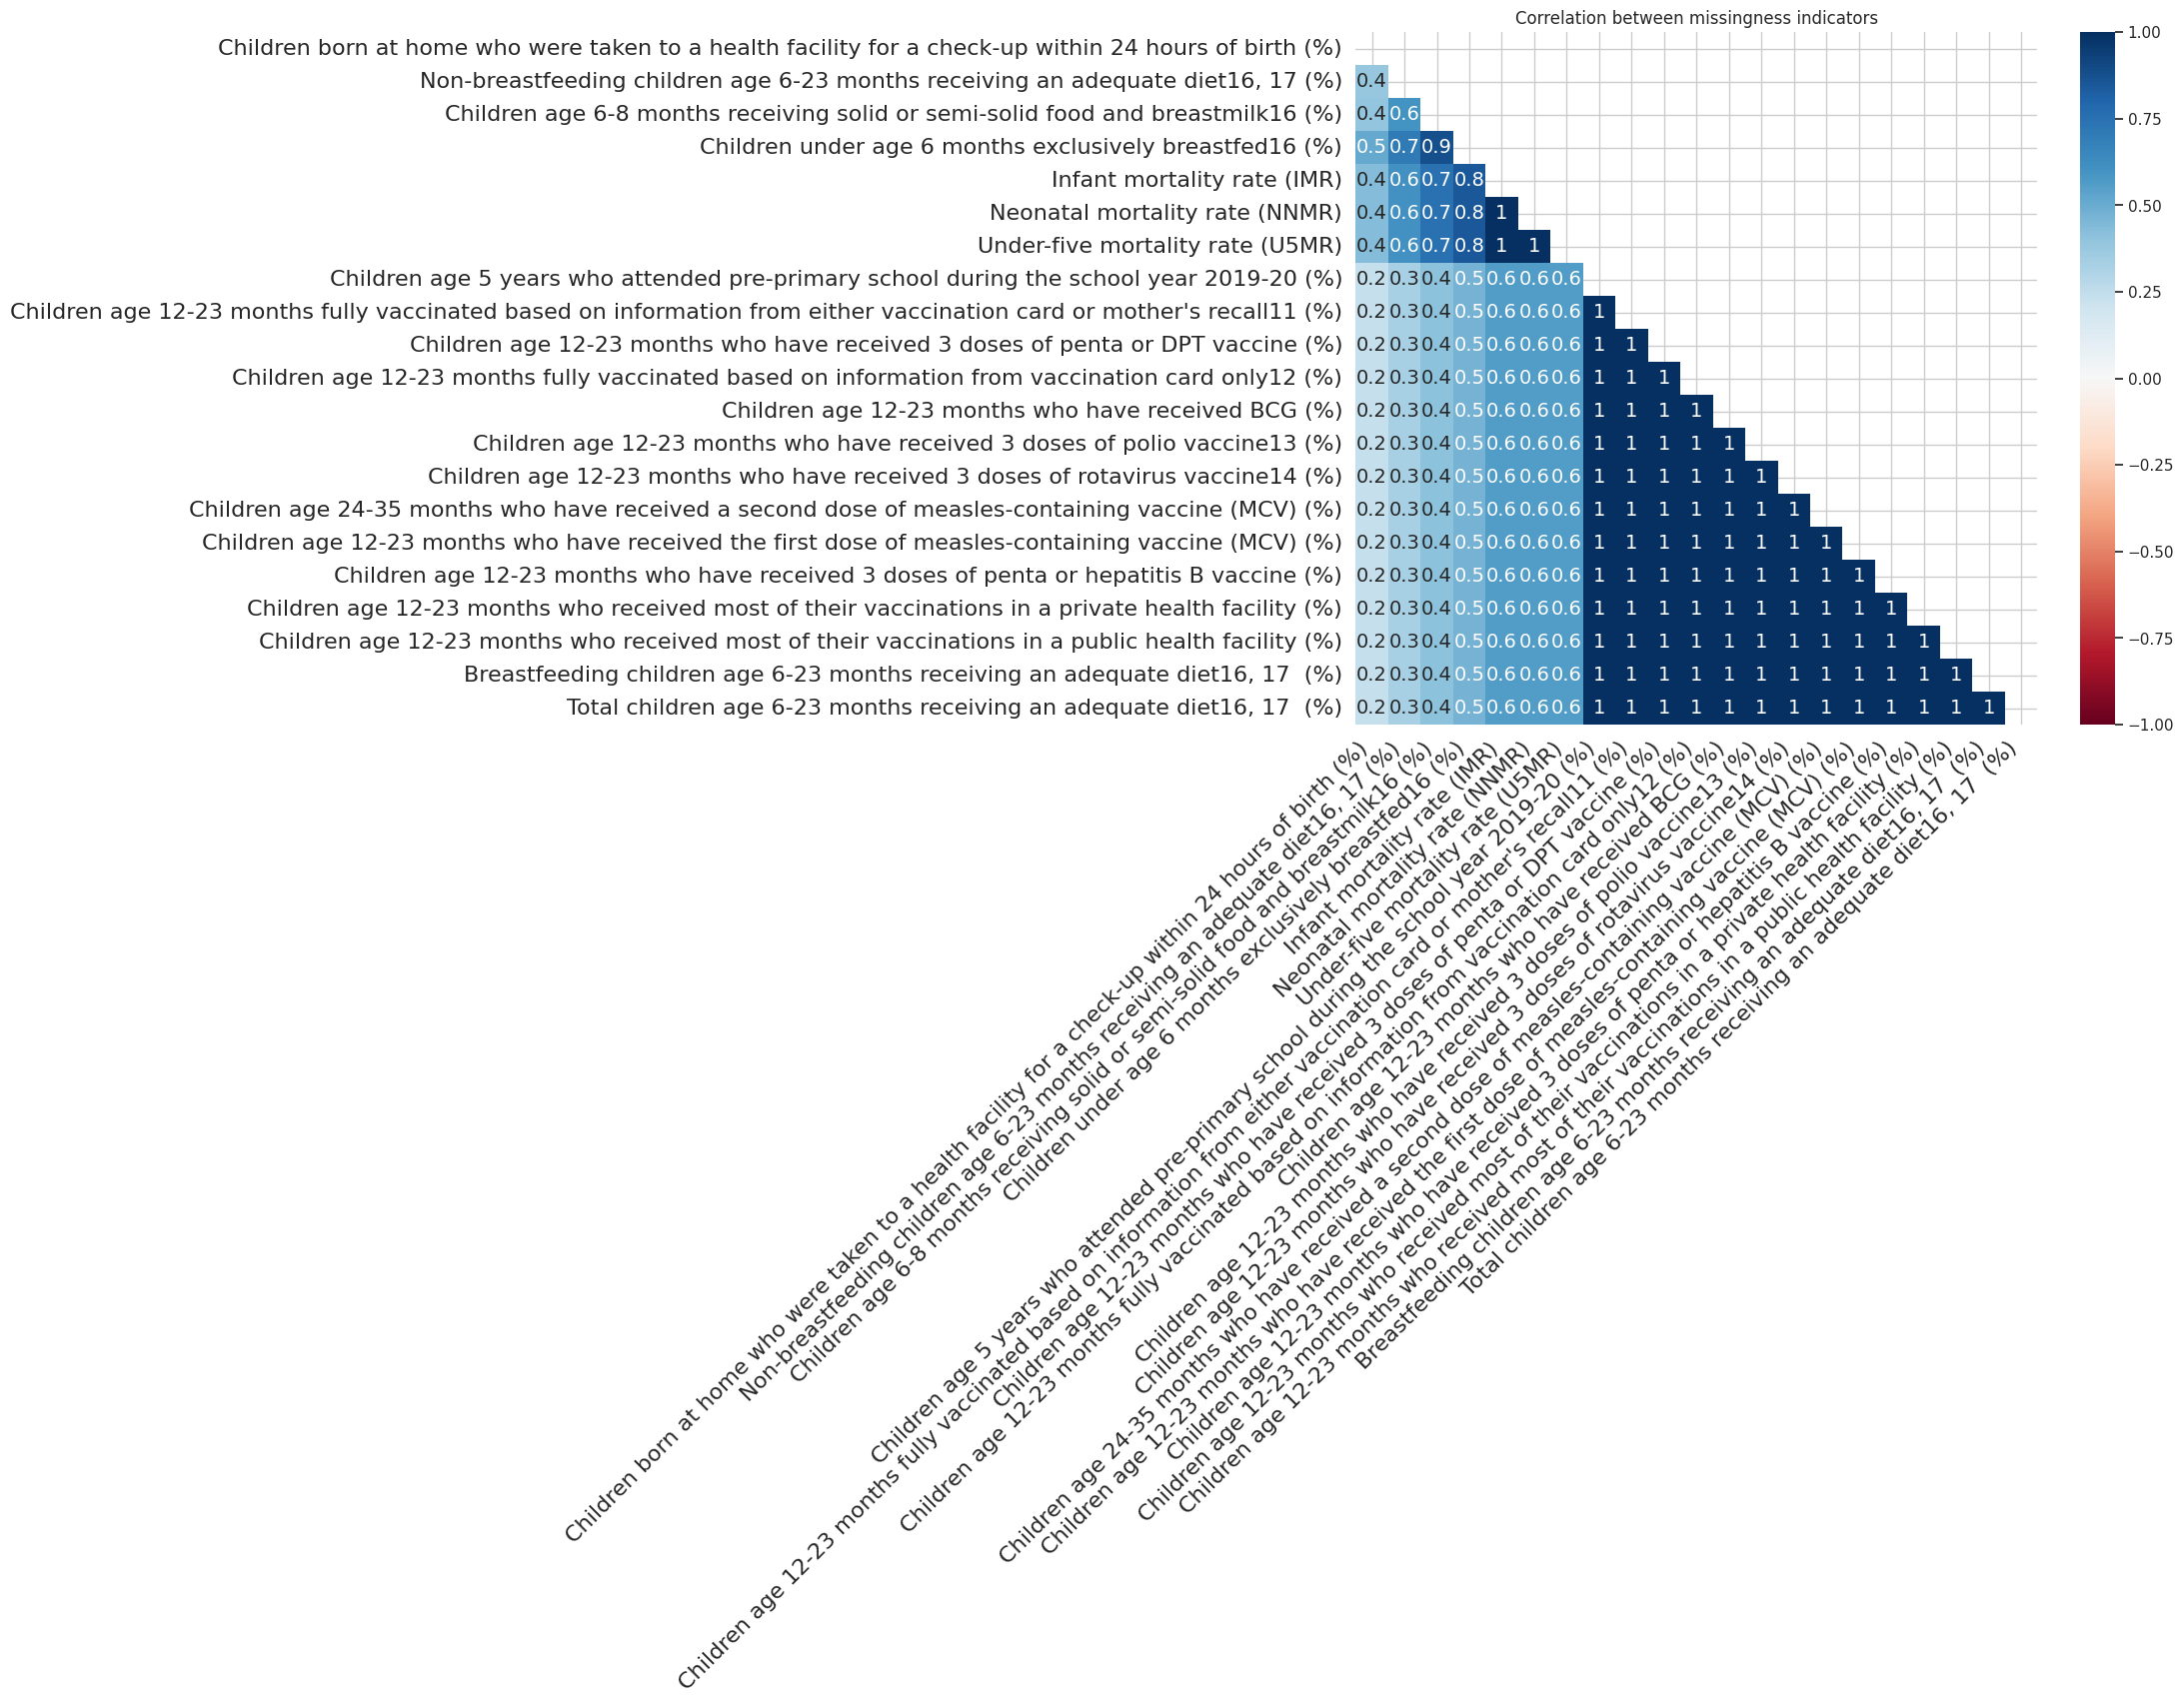

In [22]:
fig, ax = plt.subplots(figsize=(11, 9))
msno.heatmap(df[missing_cols], ax=ax, cmap="RdBu")
ax.set_title("Correlation between missingness indicators")
plt.tight_layout()
plt.show()


**Interpretation.** Most of the child-vaccination indicators, including BCG, polio, DPT,
measles, rotavirus, hepatitis B doses, and "most vaccinations received at" variants, show a
missingness correlation of close to 1.0 with each other. They are missing for the same single
state, almost certainly because that state's entire vaccination-card or recall module was
unavailable, not because ten independent indicators happened to fail at once. The three
mortality rates also co-miss perfectly with each other for the same reason, since they are
computed from the same underlying birth-history data. This block structure matters for the
imputation step below: a handful of co-missing blocks, not many independent events, are really
driving the pattern.

### Little's MCAR test (global)

Tests the null hypothesis that missingness overall is unrelated to any observed value, giving a
single p-value for the whole dataset.

In [23]:
little_input = df[numeric_cols]
little_p = MCARTest(method="little").little_mcar_test(little_input)
print(f"Little's MCAR test p-value: {little_p:.4f}")

alpha = 0.05
if little_p > alpha:
    print(f"p = {little_p:.3f} > {alpha}, fail to reject H0: globally consistent with MCAR.")
else:
    print(f"p = {little_p:.3f} <= {alpha}, reject H0: missingness is not completely random "
          f"at the global level.")


Little's MCAR test p-value: 1.0000
p = 1.000 > 0.05, fail to reject H0: globally consistent with MCAR.


**Limitation.** Little's test gives one number for the whole dataset. It has low power
at n = 29 and cannot tell us which specific column's missingness might behave differently from
the rest, so it is read here as context rather than something that should force one imputation
method on every column equally.

## Imputation

### Correlated features per column

In [24]:
def top_correlated_features(data, numeric_cols, target, n_features=6):
    corr_matrix = data[numeric_cols].corr()
    corrs = corr_matrix[target].drop(index=target).abs().sort_values(ascending=False)
    return corrs.head(n_features)

N_FEATURES = 6
feature_summary_rows = []
for col in missing_cols:
    top = top_correlated_features(df, numeric_cols, col, n_features=N_FEATURES)
    feature_summary_rows.append({
        "missing_column": col,
        "top_1": f"{top.index[0]} ({top.iloc[0]:.2f})",
        "top_2": f"{top.index[1]} ({top.iloc[1]:.2f})",
        "top_3": f"{top.index[2]} ({top.iloc[2]:.2f})",
    })

feature_summary = pd.DataFrame(feature_summary_rows).set_index("missing_column")
feature_summary


,top_1,top_2,top_3
missing_column,,,
Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%),Children age 12-23 months who received most of...,Neonatal mortality rate (NNMR) (0.48),Children age 24-35 months who have received a ...
"Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)",Total children age 6-23 months receiving an ad...,Children under age 3 years breastfed within on...,Breastfeeding children age 6-23 months receivi...
Children age 6-8 months receiving solid or semi-solid food and breastmilk16 (%),Non-breastfeeding children age 6-23 months rec...,Children under age 3 years breastfed within on...,Children under 5 years who are stunted (height...
Children under age 6 months exclusively breastfed16 (%),Institutional births (%) (0.42),Children age 5 years who attended pre-primary ...,Home births that were conducted by skilled hea...
Infant mortality rate (IMR),Under-five mortality rate (U5MR) (0.97),Neonatal mortality rate (NNMR) (0.93),Children age 6-8 months receiving solid or sem...
Neonatal mortality rate (NNMR),Infant mortality rate (IMR) (0.93),Under-five mortality rate (U5MR) (0.90),Children age 6-8 months receiving solid or sem...
Under-five mortality rate (U5MR),Infant mortality rate (IMR) (0.97),Neonatal mortality rate (NNMR) (0.90),Children under age 3 years breastfed within on...
Children age 5 years who attended pre-primary school during the school year 2019-20 (%),Sex ratio of the total population (females per...,Total children age 6-23 months receiving an ad...,Breastfeeding children age 6-23 months receivi...
Children age 12-23 months fully vaccinated based on information from either vaccination card or mother's recall11 (%),Children age 12-23 months who have received 3 ...,Children age 12-23 months who have received th...,Children age 12-23 months who have received 3 ...


### Correlation-guided KNN imputation

In [25]:
def correlated_knn_impute(data, missing_cols, numeric_cols, n_features=6, n_neighbors=5):
    data = data.copy()
    # fewest-missing-first ordering so later columns can benefit from earlier fills
    ordered_cols = (
        data[missing_cols].isna().sum().sort_values(ascending=True).index.tolist()
    )
    for target in ordered_cols:
        top_feats = top_correlated_features(data, numeric_cols, target, n_features=n_features).index.tolist()
        use_cols = [target] + top_feats

        scaler = StandardScaler()
        scaled = scaler.fit_transform(data[use_cols])

        imputer = KNNImputer(n_neighbors=n_neighbors)
        filled_scaled = imputer.fit_transform(scaled)
        filled = scaler.inverse_transform(filled_scaled)

        data[target] = filled[:, 0]
    return data

df_clean = correlated_knn_impute(df, missing_cols, numeric_cols, n_features=N_FEATURES, n_neighbors=5)

print("Remaining missing values:", df_clean[numeric_cols].isna().sum().sum())


Remaining missing values: 0


### Before and after check

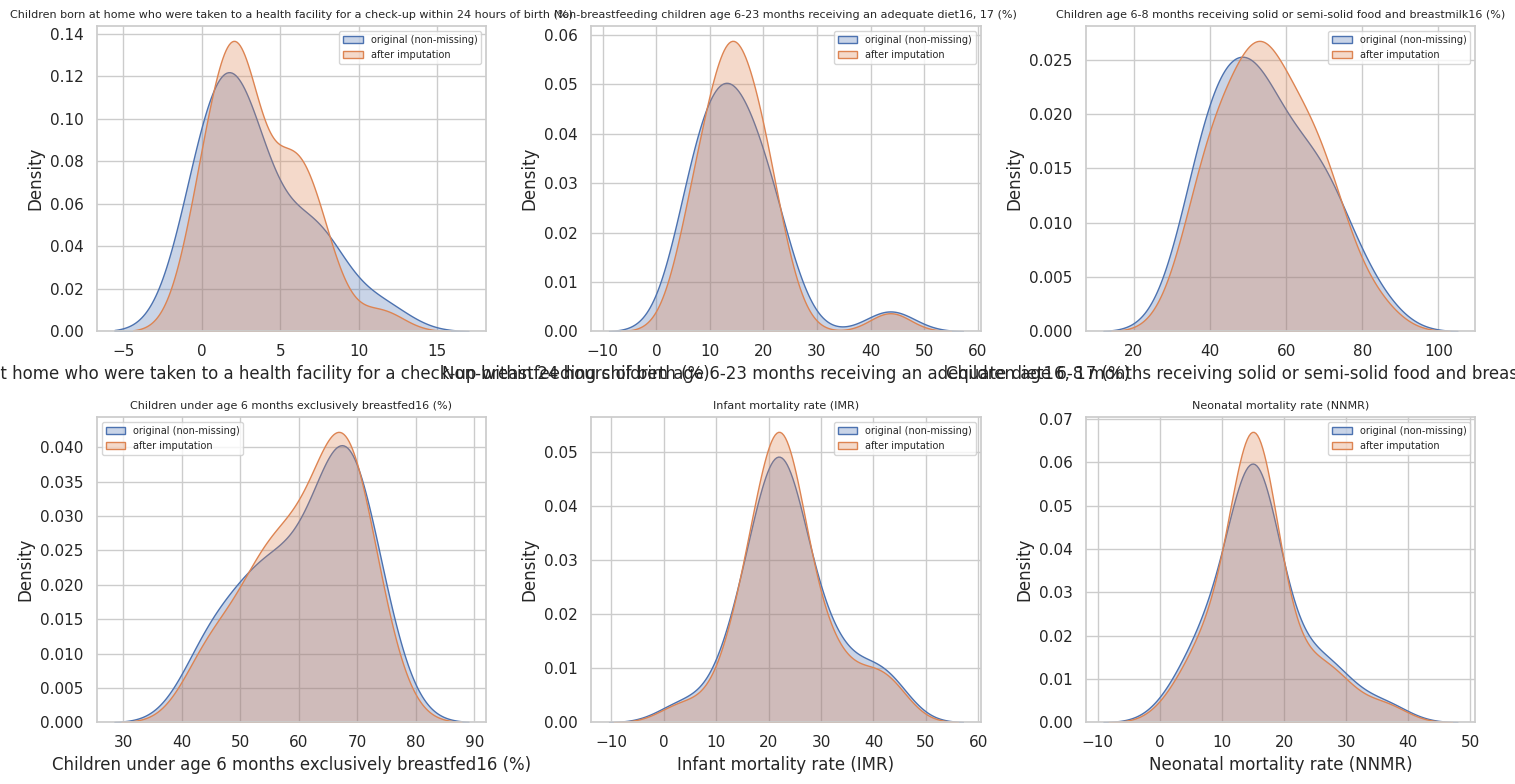

In [26]:
check_cols = missing_cols[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, check_cols):
    sns.kdeplot(df[c].dropna(), ax=ax, label="original (non-missing)", fill=True, alpha=0.3)
    sns.kdeplot(df_clean[c], ax=ax, label="after imputation", fill=True, alpha=0.3)
    ax.set_title(c, fontsize=8)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


In [27]:
missing_after = df_clean.isna().sum()
assert missing_after.sum() == 0, "Missing values remain after imputation!"
print("All missing values resolved. Final shape:", df_clean.shape)
df_clean.head()


All missing values resolved. Final shape: (29, 53)


,State,Population (Total),Accounts,Budget Estimates,Revised Estimates,Population below age 15 years (%),"Sex ratio of the total population (females per 1,000 males)","Sex ratio at birth for children born in the last five years (females per 1,000 males)",Children under age 5 years whose birth was registered with the civil authority (%),Population living in households with an improved drinking-water source1 (%),Population living in households that use an improved sanitation facility2 (%),Households using iodized salt (%),Children age 5 years who attended pre-primary school during the school year 2019-20 (%),Women age 15-19 years who were already mothers or pregnant at the time of the survey (%),Adolescent fertility rate for women age 15-19 years,Neonatal mortality rate (NNMR),Infant mortality rate (IMR),Under-five mortality rate (U5MR),Mothers who had an antenatal check-up in the first trimester (%),Mothers who had at least 4 antenatal care visits (%),Mothers whose last birth was protected against neonatal tetanus9 (%),Mothers who consumed iron folic acid for 180 days or more when they were pregnant (%),Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%),Children who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),Institutional births (%),Home births that were conducted by skilled health personnel10 (%),Children age 12-23 months fully vaccinated based on information from either vaccination card or mother's recall11 (%),Children age 12-23 months fully vaccinated based on information from vaccination card only12 (%),Children age 12-23 months who have received BCG (%),Children age 12-23 months who have received 3 doses of polio vaccine13 (%),Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%),Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%),Children age 24-35 months who have received a second dose of measles-containing vaccine (MCV) (%),Children age 12-23 months who have received 3 doses of rotavirus vaccine14 (%),Children age 12-23 months who have received 3 doses of penta or hepatitis B vaccine (%),Children age 9-59 months who received a vitamin A dose in the last 6 months (%),Children age 12-23 months who received most of their vaccinations in a public health facility (%),Children age 12-23 months who received most of their vaccinations in a private health facility (%),Prevalence of diarrhoea in the 2 weeks preceding the survey (%),Children under age 3 years breastfed within one hour of birth15 (%),Children under age 6 months exclusively breastfed16 (%),Children age 6-8 months receiving solid or semi-solid food and breastmilk16 (%),"Breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)","Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)","Total children age 6-23 months receiving an adequate diet16, 17 (%)",Children under 5 years who are stunted (height-for-age)18 (%),Children under 5 years who are wasted (weight-for-height)18 (%),Children under 5 years who are severely wasted (weight-for-height)19 (%),Children under 5 years who are underweight (weight-for-age)18 (%),Children under 5 years who are overweight (weight-for-height)20 (%),Per_Capita_Health_Exp_Accounts,Per_Capita_Health_Exp_BE,Per_Capita_Health_Exp_RE
0,Andhra Pradesh,52504000.0,525929.6,605549.45,526323.02,21.3,1024,877,93.8,99.4,89.1,89.3,10.2,9.3,40,14.4,29.8,33.7,82.7,67.2,92.5,45.6,1.0,92.9,98.6,1.0,69.3,89.1,92.4,70.6,84.8,83.7,27.1,72.0,83.0,81.7,86.4,11.5,6.2,51.6,61.4,67.3,15.2,19.50,16.7,23.1,17.6,6.4,25.1,3.0,1001.694347,1153.339650,1002.443661
1,Arunachal Pradesh,1519000.0,92615.0,131266.59,91612.20,26.2,989,912,89.7,98.1,79.9,99.4,8.0,3.2,27,12.5,16.7,22.2,57.2,47.8,82.1,13.0,7.8,66.6,90.6,3.2,66.8,73.4,93.4,70.5,83.2,85.1,29.6,28.8,80.9,75.7,99.3,0.7,4.3,54.0,66.2,42.3,26.5,16.80,25.7,28.4,10.1,4.7,13.1,9.6,6097.1

## Save the cleaned dataset

In [28]:
OUT_PATH = "budget_nfhs_combined_clean.csv"
df_clean.to_csv(OUT_PATH, index=False)
print(f"Saved cleaned data to {OUT_PATH}")


Saved cleaned data to budget_nfhs_combined_clean.csv
